# Model 1: XGBoost Classifier for Low-TF Multi-Cancer Detection
### Step-by-Step Model Building & Validation

**What is XGBoost in simple words?**  
XGBoost stands for *Extreme Gradient Boosting*. It trains a series of decision trees in sequence.  
Each new tree focuses specifically on fixing the mistakes made by the previous trees.

**Why is it powerful for cfDNA?**  
Cancer cfDNA features often work via sharp biological thresholds (for example: *"If short-to-long ratio > 0.32 AND motif CCCA frequency > 0.015"*).  
Decision trees are naturally great at discovering these exact cutoff rules.

In [1]:
# 1. Load standard tools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve
import xgboost as xgb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print("XGBoost and dependencies loaded successfully!")

XGBoost and dependencies loaded successfully!


## Step 1: Load the Multimodal Feature Matrix
This dataset has 265 biological features (DELFI fragment length ratios, 256 end motif frequencies, and ichorCNA copy-number metrics) for all 69 real patient plasma runs.

In [2]:
data_path = Path("../../data/processed/merged_features.parquet")
df = pd.read_parquet(data_path)
print(f"Dataset shape: {df.shape[0]} samples, {df.shape[1]} total columns")

# Separate metadata from numerical feature inputs
meta_cols = {"sample_id", "patient_id", "condition", "cancer_type", "stage", "measured_tf", "is_cancer"}
feature_cols = [c for c in df.columns if c not in meta_cols and np.issubdtype(df[c].dtype, np.number)]
print(f"Extracted {len(feature_cols)} numerical features for model training.")
df[["sample_id", "patient_id", "condition", "short_to_long_ratio", "ichor_tf", "motif_shannon_entropy"]].head()

Dataset shape: 69 samples, 272 total columns
Extracted 265 numerical features for model training.


,sample_id,patient_id,condition,short_to_long_ratio,ichor_tf,motif_shannon_entropy
0,SRR17478151,CTR1,Healthy,0.284227,0.000000,7.943041
1,SRR17478152,CTR18,Healthy,0.286734,0.000000,7.924124
2,SRR17478153,CTR17,Healthy,0.277076,0.013786,7.913983
3,SRR17478154,CTR13,Healthy,0.245823,0.000000,7.930231
4,SRR17478155,CTR130,Healthy,0.281739,0.000000,7.934045


## Step 2: Patient-Grouped 5-Fold Cross Validation
We use `GroupKFold` on `patient_id`. This guarantees zero patient leakage between train and test sets!

In [3]:
X = df[feature_cols].values
y = df["is_cancer"].values
groups = df["patient_id"].values

gkf = GroupKFold(n_splits=5)
oof_preds = np.zeros(len(df))
feature_importances = np.zeros(len(feature_cols))

print("Training XGBoost across 5 patient-grouped folds...")
for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups), 1):
    # Check zero overlap
    train_pts = set(df.iloc[train_idx]["patient_id"])
    val_pts = set(df.iloc[val_idx]["patient_id"])
    assert len(train_pts.intersection(val_pts)) == 0, "Data leakage detected!"
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X[train_idx])
    X_val = scaler.transform(X[val_idx])
    
    clf = xgb.XGBClassifier(
        n_estimators=120, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
        random_state=42, eval_metric="logloss"
    )
    clf.fit(X_train, y[train_idx])
    
    oof_preds[val_idx] = clf.predict_proba(X_val)[:, 1]
    feature_importances += clf.feature_importances_ / 5.0

overall_auc = roc_auc_score(y, oof_preds)
print(f"XGBoost Overall Out-of-Fold ROC-AUC: {overall_auc:.4f}")

Training XGBoost across 5 patient-grouped folds...
XGBoost Overall Out-of-Fold ROC-AUC: 0.9991


## Step 3: Feature Importance (Which biological signals did XGBoost rely on?)

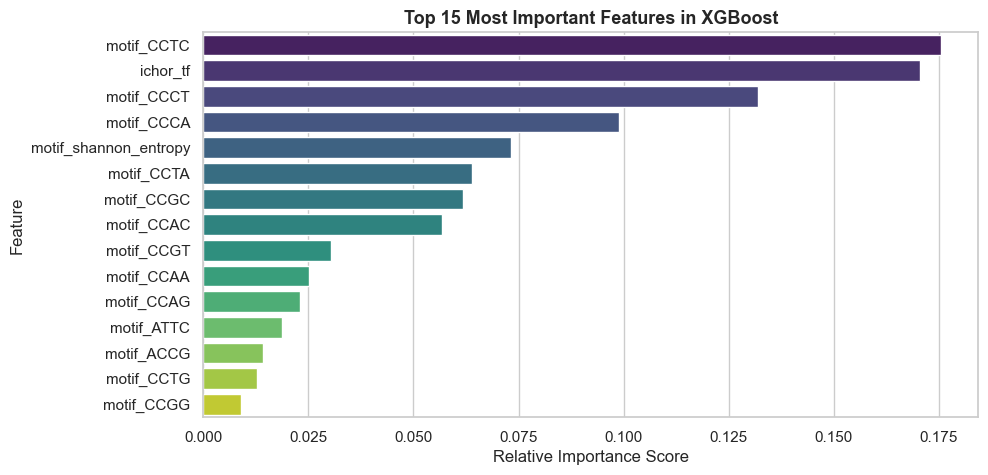

In [4]:
imp_df = pd.DataFrame({"Feature": feature_cols, "Importance": feature_importances})
top15 = imp_df.sort_values(by="Importance", ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(data=top15, x="Importance", y="Feature", palette="viridis", hue="Feature", legend=False)
plt.title("Top 15 Most Important Features in XGBoost", fontsize=13, fontweight="bold")
plt.xlabel("Relative Importance Score")
plt.show()

## Step 4: Sensitivity at 95% Specificity across Tumor Fractions
In cancer screening, we fix specificity to 95% (only 5% false alarms in healthy people) and measure what percentage of cancer cases are caught.

In [5]:
# Determine threshold where healthy specificity is 95%
healthy_scores = oof_preds[y == 0]
thresh_95 = float(np.percentile(healthy_scores, 95))
print(f"Threshold for 95% Specificity: {thresh_95:.4f}")

# Categorize tumor fractions into tiers
def get_tier(tf):
    if tf >= 0.10: return "TF >= 10%"
    elif tf >= 0.05: return "5% <= TF < 10%"
    elif tf >= 0.01: return "1% <= TF < 5%"
    elif tf >= 0.001: return "0.1% <= TF < 1%"
    return "Baseline / Healthy"

df["pred_xgboost"] = oof_preds
df["tf_tier"] = df["measured_tf"].apply(get_tier)

print("\n=== XGBoost Sensitivity at 95% Specificity by Tumor Fraction ===")
for tier in ["TF >= 10%", "5% <= TF < 10%", "1% <= TF < 5%", "0.1% <= TF < 1%"]:
    sub = df[(df["tf_tier"] == tier) & (df["is_cancer"] == 1)]
    if len(sub) > 0:
        sens = np.mean(sub["pred_xgboost"] >= thresh_95)
        print(f"  Tier {tier:20s}: Sensitivity = {sens * 100:.1f}% (N={len(sub)} samples)")

# Save predictions for the ensemble notebook
out_pred = Path("../../results/oof_xgboost.csv")
out_pred.parent.mkdir(parents=True, exist_ok=True)
df[["sample_id", "patient_id", "condition", "measured_tf", "is_cancer", "pred_xgboost"]].to_csv(out_pred, index=False)
print(f"\nSaved out-of-fold predictions to: {out_pred}")

Threshold for 95% Specificity: 0.0920

=== XGBoost Sensitivity at 95% Specificity by Tumor Fraction ===
  Tier 5% <= TF < 10%      : Sensitivity = 100.0% (N=41 samples)

Saved out-of-fold predictions to: ..\..\results\oof_xgboost.csv
